# Classroom Insights from CCTV Footage with a CNN
### A beginner-friendly Data Analyst project (Google Colab)

**What this project does:** takes classroom camera footage and turns it into *numbers a teacher or school can use*:

| Insight | How we get it |
|---|---|
| 👥 **Attendance** (how many students are present) | Detect every person in each frame and count them |
| 🙋 **Raising hand** | Detect body "skeleton" points; hand raised = wrist is above the shoulder |
| 😴📱💻💬 **Behaviour** (sleeping, phone use, working on laptop, talking/laughing, sitting attentively) | A **CNN** (Convolutional Neural Network) that we train ourselves |

### The pipeline (read this first!)
```
 Video  ──►  Pick a frame every few seconds  ──►  Find every person (YOLO)
                                                      │
                          ┌───────────────────────────┼───────────────────────────┐
                          ▼                           ▼                           ▼
                  Count people                 Skeleton points              Crop each person
                  = ATTENDANCE                 = HAND RAISED?               ──► our CNN ──► BEHAVIOUR
                          └───────────────────────────┴───────────────────────────┘
                                                      ▼
                                      Table (pandas) ──► Charts ──► Insights
```

### ⚠️ Please read: honesty & ethics notes
1. **Dataset:** there is no freely downloadable, no-login dataset of real classroom CCTV with all the behaviours we want. So we train on the public **Human Action Recognition** dataset (Hugging Face), which has photos of people sleeping, texting, using a laptop, laughing, sitting. It's a **stand-in** to learn the workflow. For real use you'd label your own classroom crops (the last section explains how).
2. **"Reading" and "raising hand"** are not classes in that dataset. Hand-raising is handled with pose detection. Reading would need your own labelled images (an exercise at the end).
3. **Attendance here = headcount**, not "who attended". Identifying individuals needs face recognition, which has serious privacy and legal implications.
4. **Privacy:** filming students and analysing them needs consent and must follow your school's and country's rules (e.g. Kenya's Data Protection Act). Never use this to punish or rank individual students. Use it for *class-level* insights.

> **How to use this notebook:** Runtime ▸ Change runtime type ▸ **T4 GPU**, then run each cell top to bottom (Shift+Enter). Read the explanation above each cell as you go.

## Step 1 · Install the tools
Colab already has TensorFlow, pandas, matplotlib and OpenCV. We add two more:
- **datasets** → downloads the training dataset in one line
- **ultralytics** → gives us YOLO, a pre-trained model that finds people and body keypoints

In [1]:
!pip install -q datasets ultralytics

## Step 2 · Import libraries
Each library has a job:
- `numpy`, `pandas` → numbers and tables
- `matplotlib`, `seaborn` → charts
- `tensorflow.keras` → build and train the CNN
- `cv2` (OpenCV) → read video, draw boxes
- `sklearn` → split data, measure accuracy

In [2]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from datasets import load_dataset

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)   # makes results repeatable
print("TensorFlow:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Step 3 · Download the dataset
We use `Bingsu/Human_Action_Recognition` from Hugging Face: about 12,600 training photos and 5,400 test photos of people doing 15 actions. No account or API key needed.

Every row has an **image** and a **label** (a number that maps to an action name).

In [3]:
ds = load_dataset("Bingsu/Human_Action_Recognition")
print(ds)
label_names = ds["train"].features["labels"].names
print("\nAll 15 actions in the dataset:\n", label_names)

README.md:   0%|          | 0.00/4.70k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  229MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 98.1MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/12600 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5400 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'labels'],
        num_rows: 12600
    })
    test: Dataset({
        features: ['image', 'labels'],
        num_rows: 5400
    })
})

All 15 actions in the dataset:
 ['calling', 'clapping', 'cycling', 'dancing', 'drinking', 'eating', 'fighting', 'hugging', 'laughing', 'listening_to_music', 'running', 'sitting', 'sleeping', 'texting', 'using_laptop']


## Step 4 · Choose the behaviours relevant to a classroom
We keep 5 actions and give them *classroom-friendly names*:

| Dataset label | Classroom meaning |
|---|---|
| `sitting` | 🧍 Sitting / attentive |
| `sleeping` | 😴 Sleeping |
| `texting` | 📱 Using phone |
| `using_laptop` | 💻 Working on laptop |
| `laughing` | 💬 Talking / laughing |

> The `filter` below uses only the label column, so it's fast (it doesn't need to open every image).

In [4]:
KEEP = ["sitting", "sleeping", "texting", "using_laptop", "laughing"]
FRIENDLY = {"sitting":"Attentive", "sleeping":"Sleeping", "texting":"Phone use",
            "using_laptop":"Laptop work", "laughing":"Talking/Laughing"}
CLASSES = [FRIENDLY[k] for k in KEEP]          # order = the numbers 0..4 the CNN will output
keep_ids = {label_names.index(k) for k in KEEP}

train_raw = ds["train"].filter(lambda l: l in keep_ids, input_columns="labels")
test_raw  = ds["test"].filter(lambda l: l in keep_ids, input_columns="labels")
print("Train images kept:", len(train_raw), "| Test images kept:", len(test_raw))

Filter:   0%|          | 0/12600 [00:00<?, ? examples/s]

Filter:   0%|          | 0/5400 [00:00<?, ? examples/s]

Train images kept: 4200 | Test images kept: 0


## Step 5 · Explore the data (always do this before modelling!)
A data analyst's first job: *look at the data.* We check:
1. **Class balance**: if one class has 10× more images, the model will favour it.
2. **Sample images**: do the labels look right?

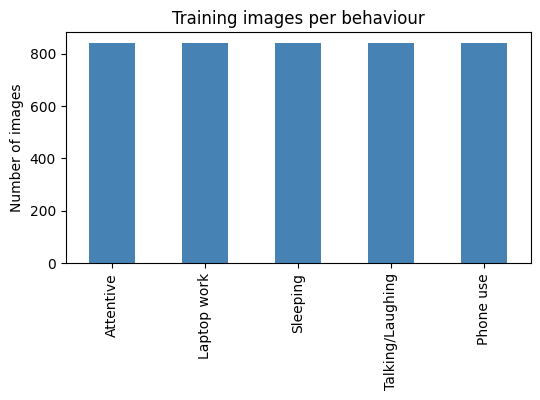

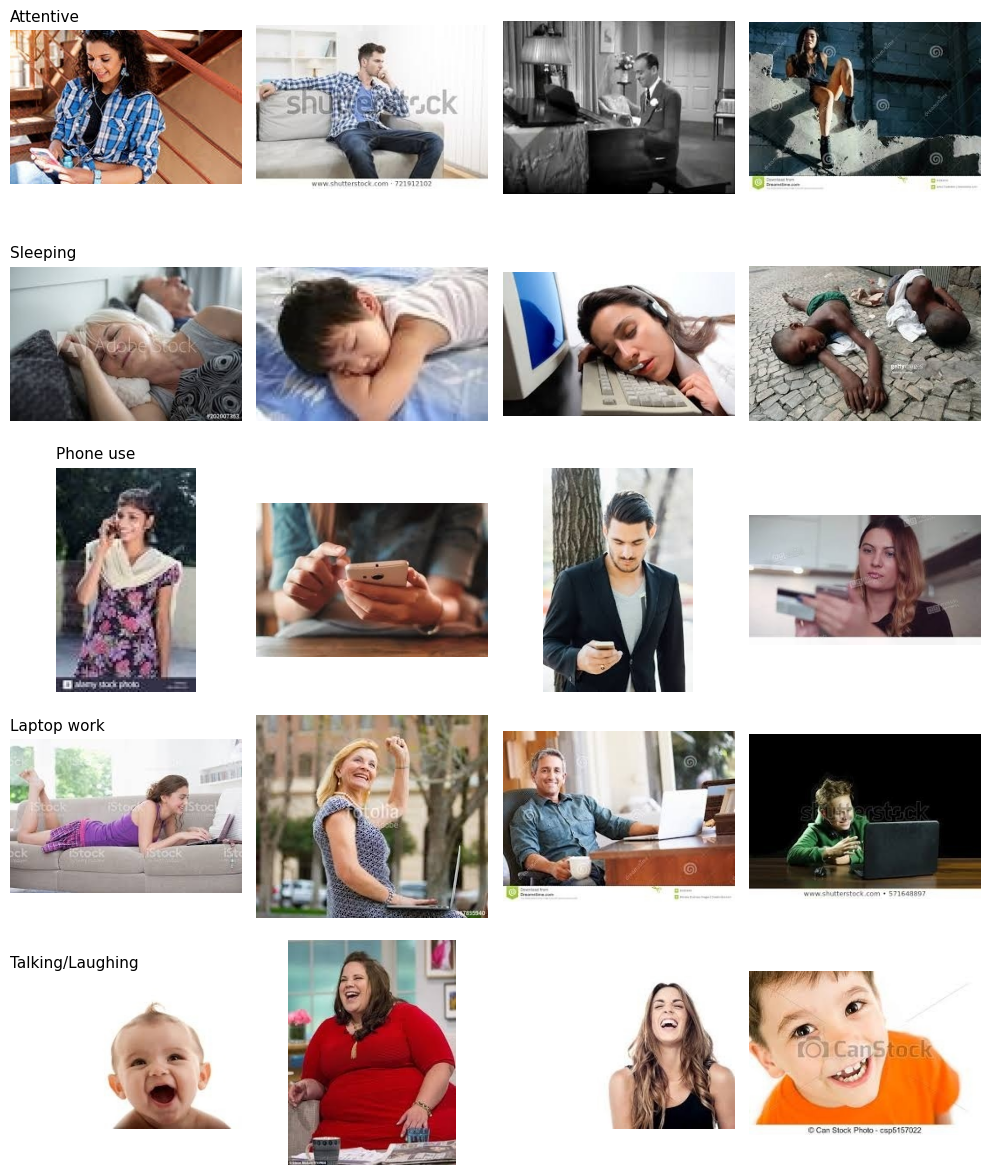

In [5]:
counts = pd.Series([label_names[l] for l in train_raw["labels"]]).value_counts()
counts.index = [FRIENDLY[i] for i in counts.index]
counts.plot(kind="bar", color="steelblue", figsize=(6,3), title="Training images per behaviour")
plt.ylabel("Number of images"); plt.show()

fig, axes = plt.subplots(len(KEEP), 4, figsize=(10, 2.4*len(KEEP)))
for r, name in enumerate(KEEP):
    idxs = [i for i, l in enumerate(train_raw["labels"]) if label_names[l] == name][:4]
    for c, i in enumerate(idxs):
        axes[r, c].imshow(train_raw[i]["image"]); axes[r, c].axis("off")
    axes[r, 0].set_title(FRIENDLY[name], loc="left", fontsize=11)
plt.tight_layout(); plt.show()

## Step 6 · Turn images into numbers
A CNN can't read JPEGs, it reads **arrays of numbers**. We:
1. Convert every image to RGB.
2. **Resize** to 160×160 pixels (CNNs need all inputs to be the same size).
3. Store as a NumPy array of shape `(num_images, 160, 160, 3)`: height, width, 3 colour channels.

Then we split the training data into **train (80%)** and **validation (20%)**:
- *train* → the model learns from this
- *validation* → we check progress on images it has **not** learned from (to detect overfitting)
- *test* → untouched until the very end, for an honest final score

In [6]:
IMG = 160

def to_arrays(split):
    X, y = [], []
    for ex in split:
        img = ex["image"].convert("RGB").resize((IMG, IMG))
        X.append(np.array(img))
        y.append(KEEP.index(label_names[ex["labels"]]))
    return np.array(X, dtype="uint8"), np.array(y)

X_all, y_all = to_arrays(train_raw)
X_test, y_test = to_arrays(test_raw)
X_train, X_val, y_train, y_val = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=SEED)

print("Train:", X_train.shape, "| Validation:", X_val.shape, "| Test:", X_test.shape)

Train: (3360, 160, 160, 3) | Validation: (840, 160, 160, 3) | Test: (0,)


## Step 7 · What is a CNN? (plain-English version)

A **Convolutional Neural Network** looks at an image the way you'd scan a photo with a small magnifying glass:

1. **Convolution layers** slide small filters (e.g. 3×3 pixels) over the image. Early filters detect simple things like edges; deeper ones detect eyes, hands, a laptop, closed eyelids.
2. **Pooling layers** shrink the image, keeping the strongest signals, which makes the model faster and less sensitive to exact position.
3. **Dense (fully connected) layers** at the end combine everything and output a **probability for each class** (e.g. 85% sleeping, 10% sitting…).

### Transfer learning: the shortcut we use
Training a CNN from scratch needs millions of images. Instead we borrow **MobileNetV2**, a CNN already trained on 1.4 million everyday images (ImageNet). It already "knows" edges, shapes and textures. We:
- **freeze** its knowledge,
- add our own small classification layers on top,
- train only those layers on our 5 behaviours.

We also use **data augmentation**: random flips, small rotations and zooms create new variations of each image on the fly, so the model doesn't just memorise the training photos.

In [7]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
], name="augmentation")

base = keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), include_top=False, weights="imagenet")
base.trainable = False                       # freeze the pre-trained knowledge

inputs = keras.Input(shape=(IMG, IMG, 3))
x = augment(inputs)                          # only active during training
x = keras.applications.mobilenet_v2.preprocess_input(x)   # scales pixels the way MobileNet expects
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)       # squash feature maps into one vector
x = layers.Dropout(0.3)(x)                   # randomly ignore 30% of neurons -> reduces overfitting
outputs = layers.Dense(len(CLASSES), activation="softmax")(x)   # 5 probabilities that add up to 1
model = keras.Model(inputs, outputs)

model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",   # standard loss for integer class labels
              metrics=["accuracy"])
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## Step 8 · Train the model
- **Epoch** = one full pass through all training images.
- **EarlyStopping** stops training when validation performance stops improving and restores the best version.
- Watch two numbers: `accuracy` (training) and `val_accuracy` (unseen data). If training keeps climbing while validation stalls → **overfitting**.

In [8]:
early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                    epochs=12, batch_size=32, callbacks=[early])

Epoch 1/12
105/105 ━━━━━━━━━━━━━━━━━━━━ 17s 66ms/step - accuracy: 0.4652 - loss: 1.4312 - val_accuracy: 0.7024 - val_loss: 0.8301
Epoch 2/12
105/105 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - accuracy: 0.6396 - loss: 0.9652 - val_accuracy: 0.7143 - val_loss: 0.7833
Epoch 3/12
105/105 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - accuracy: 0.6878 - loss: 0.8479 - val_accuracy: 0.7250 - val_loss: 0.7652
Epoch 4/12
105/105 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - accuracy: 0.7036 - loss: 0.8051 - val_accuracy: 0.7405 - val_loss: 0.7367
Epoch 5/12
105/105 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - accuracy: 0.7092 - loss: 0.7682 - val_accuracy: 0.7429 - val_loss: 0.7376
Epoch 6/12
105/105 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - accuracy: 0.7185 - loss: 0.7546 - val_accuracy: 0.7393 - val_loss: 0.7434
Epoch 7/12
105/105 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.7241 - loss: 0.7456 - val_accuracy: 0.7476 - val_loss: 0.7502


### Optional · Fine-tuning (squeezing out extra accuracy)
Now that our new layers are trained, we **unfreeze the last part of MobileNet** and train gently (very small learning rate) so it adapts to *our* behaviours. This often adds a few percentage points.

In [9]:
base.trainable = True
for layer in base.layers[:-30]:      # keep the first layers frozen, adapt only the last 30
    layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5),     # tiny steps so we don't destroy what it learned
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history_ft = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                       epochs=8, batch_size=32, callbacks=[early])

Epoch 1/8
105/105 ━━━━━━━━━━━━━━━━━━━━ 15s 64ms/step - accuracy: 0.6446 - loss: 0.9622 - val_accuracy: 0.7440 - val_loss: 0.7212
Epoch 2/8
105/105 ━━━━━━━━━━━━━━━━━━━━ 5s 47ms/step - accuracy: 0.6699 - loss: 0.8668 - val_accuracy: 0.7583 - val_loss: 0.7145
Epoch 3/8
105/105 ━━━━━━━━━━━━━━━━━━━━ 5s 50ms/step - accuracy: 0.6964 - loss: 0.7886 - val_accuracy: 0.7571 - val_loss: 0.7054
Epoch 4/8
105/105 ━━━━━━━━━━━━━━━━━━━━ 10s 49ms/step - accuracy: 0.7193 - loss: 0.7517 - val_accuracy: 0.7679 - val_loss: 0.6980
Epoch 5/8
105/105 ━━━━━━━━━━━━━━━━━━━━ 5s 50ms/step - accuracy: 0.7152 - loss: 0.7606 - val_accuracy: 0.7667 - val_loss: 0.6916
Epoch 6/8
105/105 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - accuracy: 0.7378 - loss: 0.7045 - val_accuracy: 0.7667 - val_loss: 0.6825
Epoch 7/8
105/105 ━━━━━━━━━━━━━━━━━━━━ 6s 59ms/step - accuracy: 0.7521 - loss: 0.6718 - val_accuracy: 0.7690 - val_loss: 0.6769
Epoch 8/8
105/105 ━━━━━━━━━━━━━━━━━━━━ 6s 56ms/step - accuracy: 0.7616 - loss: 0.6520 - val_accuracy: 

## Step 9 · Training curves
**How to read them:**
- Both lines rising and close together ✅ healthy.
- Training much higher than validation ⚠️ overfitting.
- Both low ⚠️ underfitting (model too simple, or needs more training or better data).

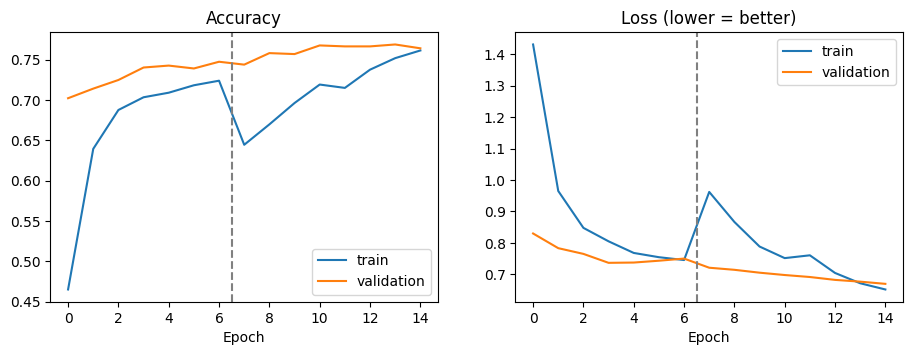

In [10]:
acc  = history.history["accuracy"] + history_ft.history["accuracy"]
vacc = history.history["val_accuracy"] + history_ft.history["val_accuracy"]
loss = history.history["loss"] + history_ft.history["loss"]
vloss= history.history["val_loss"] + history_ft.history["val_loss"]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(acc, label="train"); ax[0].plot(vacc, label="validation"); ax[0].set_title("Accuracy")
ax[1].plot(loss, label="train"); ax[1].plot(vloss, label="validation"); ax[1].set_title("Loss (lower = better)")
for a in ax:
    a.set_xlabel("Epoch"); a.legend()
    a.axvline(len(history.history["accuracy"])-0.5, color="gray", ls="--")   # where fine-tuning began
plt.show()

## Step 10 · Final exam: evaluate on the test set
The test set was never used during training or tuning, so this is our honest score.

- **Accuracy**: % of images classified correctly.
- **Precision**: when the model says "sleeping", how often is it right?
- **Recall**: of all truly sleeping students, how many did it catch?
- **Confusion matrix**: rows = true class, columns = predicted. The diagonal is correct; off-diagonal cells show *which behaviours get mixed up*.

In [14]:
IMG = 160

def to_arrays(split):
    X, y = [], []
    for ex in split:
        img = ex["image"].convert("RGB").resize((IMG, IMG))
        X.append(np.array(img))
        y.append(KEEP.index(label_names[ex["labels"]]))
    return np.array(X, dtype="uint8"), np.array(y)

X_all, y_all = to_arrays(train_raw)

# 70% train / 15% validation / 15% test, all from the labelled data
X_train, X_temp, y_train, y_temp = train_test_split(X_all, y_all, test_size=0.30, stratify=y_all, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

print("Train:", X_train.shape, "| Validation:", X_val.shape, "| Test:", X_test.shape)


Train: (2940, 160, 160, 3) | Validation: (630, 160, 160, 3) | Test: (630, 160, 160, 3)


✅ Test accuracy: 77.9%

                  precision    recall  f1-score   support

       Attentive       0.76      0.76      0.76       126
        Sleeping       0.86      0.80      0.83       126
       Phone use       0.74      0.68      0.71       126
     Laptop work       0.73      0.78      0.75       126
Talking/Laughing       0.81      0.87      0.84       126

        accuracy                           0.78       630
       macro avg       0.78      0.78      0.78       630
    weighted avg       0.78      0.78      0.78       630



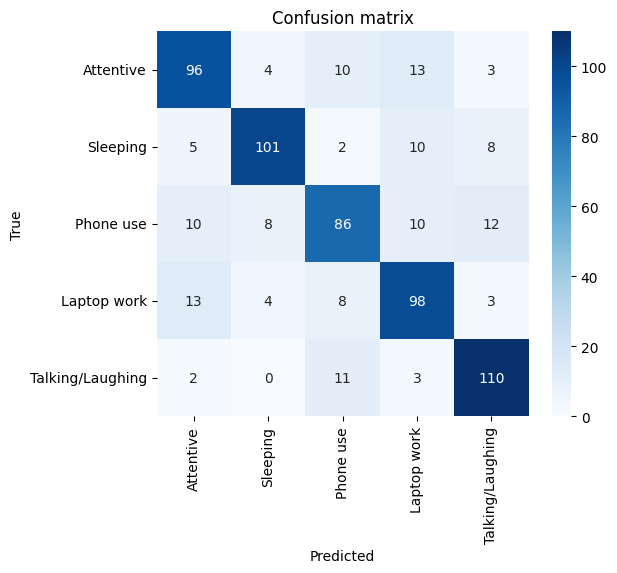

In [15]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"✅ Test accuracy: {test_acc:.1%}\n")

y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
print(classification_report(y_test, y_pred, target_names=CLASSES))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix"); plt.show()

### Error analysis
Remember the framework: *numbers tell you how much, examples tell you why.* Look at these and ask: is the image ambiguous? Is the label wrong? Is the person partly hidden?

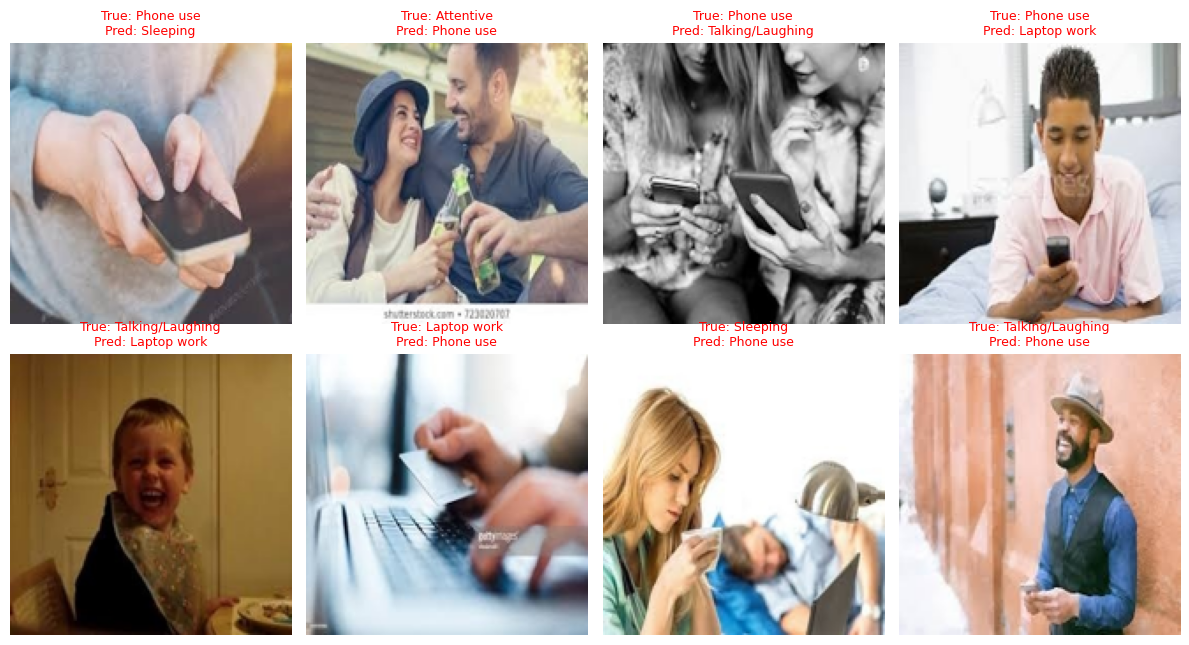

Model saved ✔  (download it from the Files panel on the left if you want to keep it)


In [16]:
wrong = np.where(y_pred != y_test)[0]
sel = np.random.choice(wrong, size=min(8, len(wrong)), replace=False)
fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))
for a, i in zip(axes.ravel(), sel):
    a.imshow(X_test[i]); a.axis("off")
    a.set_title(f"True: {CLASSES[y_test[i]]}\nPred: {CLASSES[y_pred[i]]}", fontsize=9, color="red")
plt.tight_layout(); plt.show()

model.save("classroom_behaviour_cnn.keras")
print("Model saved ✔  (download it from the Files panel on the left if you want to keep it)")

## Step 11 · Find people and hand-raises with YOLO-Pose
Our CNN classifies **one person at a time**, but a CCTV frame has many students. So first we need a model that:
1. **Finds every person** → draws a box around each (this gives us **attendance**).
2. Finds **17 body keypoints** per person (nose, shoulders, elbows, wrists, …).

We use **YOLOv8-pose**, which is pre-trained and downloads automatically.

**Hand-raise rule:** in images, y = 0 is the *top*. So if a wrist's y-value is **smaller** than the same-side shoulder's y-value, the wrist is higher up → hand raised.

In [17]:
from ultralytics import YOLO
yolo = YOLO("yolov8n-pose.pt")     # "n" = nano: small and fast

L_SHOULDER, R_SHOULDER, L_WRIST, R_WRIST = 5, 6, 9, 10   # COCO keypoint numbers

def hand_is_raised(kpts, min_conf=0.5, margin=10):
    """kpts: array (17, 3) -> x, y, confidence for each keypoint."""
    for wrist, shoulder in ((L_WRIST, L_SHOULDER), (R_WRIST, R_SHOULDER)):
        wx, wy, wc = kpts[wrist]; sx, sy, sc = kpts[shoulder]
        if wc > min_conf and sc > min_conf and wy < sy - margin:   # wrist above shoulder
            return True
    return False

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


## Step 12 · Combine everything into one function
`analyze_frame(frame)` does the whole pipeline for a single image and returns **one row per detected person**:
`box → crop → CNN behaviour + confidence → hand raised?`

> ⚠️ We apply the CNN to *cropped people*, but trained on whole photos of people. This mismatch is a known limitation (see the final section).

In [18]:
def analyze_frame(frame_bgr, conf_thresh=0.4):
    """Return a list of dicts, one per person found in the frame."""
    results = yolo(frame_bgr, verbose=False, conf=conf_thresh)[0]
    people = []
    if results.boxes is None or len(results.boxes) == 0:
        return people
    boxes = results.boxes.xyxy.cpu().numpy().astype(int)
    kpts_all = results.keypoints.data.cpu().numpy()
    h, w = frame_bgr.shape[:2]
    for box, kpts in zip(boxes, kpts_all):
        x1, y1, x2, y2 = np.clip(box, 0, [w, h, w, h])
        if (x2 - x1) < 20 or (y2 - y1) < 20:
            continue                                            # ignore tiny detections
        crop = cv2.cvtColor(frame_bgr[y1:y2, x1:x2], cv2.COLOR_BGR2RGB)
        crop = cv2.resize(crop, (IMG, IMG)).astype("float32")
        probs = model.predict(crop[None], verbose=0)[0]
        people.append({"box": (x1, y1, x2, y2),
                       "behaviour": CLASSES[int(np.argmax(probs))],
                       "confidence": float(np.max(probs)),
                       "hand_raised": hand_is_raised(kpts)})
    return people

COLORS = {"Attentive":(60,180,75), "Sleeping":(230,25,75), "Phone use":(245,130,48),
          "Laptop work":(0,130,200), "Talking/Laughing":(145,30,180)}

def draw(frame_bgr, people):
    out = frame_bgr.copy()
    for p in people:
        x1, y1, x2, y2 = p["box"]
        col = COLORS[p["behaviour"]][::-1]                      # RGB -> BGR for OpenCV
        cv2.rectangle(out, (x1, y1), (x2, y2), col, 2)
        label = p["behaviour"] + (" + HAND UP" if p["hand_raised"] else "")
        cv2.putText(out, label, (x1, max(15, y1-5)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, col, 2)
    cv2.putText(out, f"Present: {len(people)}", (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255,255,255), 2)
    return out

## Step 13 · Try it on a single frame
We don't have real CCTV footage yet, so we build a **pretend classroom frame** by tiling 6 test photos together. It's only for testing the pipeline. Later you can use your own video.

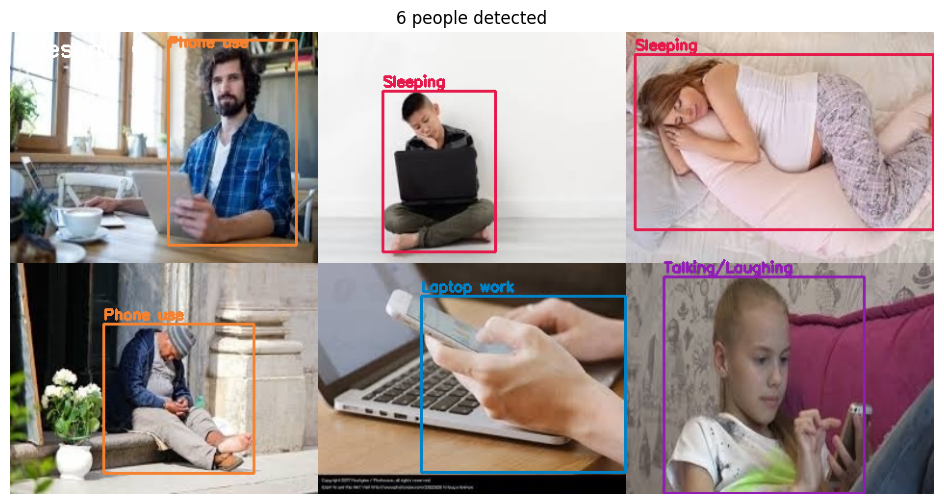

,behaviour,confidence,hand_raised
0,Phone use,0.791846,False
1,Sleeping,0.511474,False
2,Sleeping,0.994410,False
3,Talking/Laughing,0.594712,False
4,Laptop work,0.508775,False
5,Phone use,0.621542,False


In [20]:
def fake_classroom_frame(seed=None):
    rng = random.Random(seed)
    idx = rng.sample(range(len(train_raw)), 6)
    tiles = [cv2.resize(cv2.cvtColor(np.array(train_raw[i]["image"].convert("RGB")), cv2.COLOR_RGB2BGR), (320, 240)) for i in idx]
    return np.vstack([np.hstack(tiles[:3]), np.hstack(tiles[3:])])

frame = fake_classroom_frame(seed=1)
people = analyze_frame(frame)
plt.figure(figsize=(12, 6)); plt.imshow(cv2.cvtColor(draw(frame, people), cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.title(f"{len(people)} people detected"); plt.show()
pd.DataFrame(people)[["behaviour", "confidence", "hand_raised"]] if people else print("No people found, try another seed")

## Step 14 · Test
CCTV video has ~25 frames per second, and analysing every one is wasteful (nothing changes in 1/25 s). We **sample one frame every N seconds** (default 5).

Two options:
- **Option A (default):** simulated 'lesson' made of 12 fake frames, so the notebook runs end-to-end immediately.
- **Option B:** upload your own `.mp4`: set `USE_OWN_VIDEO = True`, run the cell, and choose a file. *(Only use footage you have permission to analyse.)*

Every detection is stored as a row in a pandas **DataFrame**: our dataset for analysis.

In [23]:
def fake_classroom_frame(seed=None):
    rng = random.Random(seed)
    idx = rng.sample(range(len(train_raw)), 6)      # train_raw, NOT test_raw
    tiles = [cv2.resize(cv2.cvtColor(np.array(train_raw[i]["image"].convert("RGB")), cv2.COLOR_RGB2BGR), (320, 240)) for i in idx]
    return np.vstack([np.hstack(tiles[:3]), np.hstack(tiles[3:])])

print("Images available:", len(train_raw))          # should be a few thousand
test_frame = fake_classroom_frame(seed=1)
print("Frame OK, shape:", test_frame.shape)         # should be (480, 960, 3)

Images available: 4200
Frame OK, shape: (480, 960, 3)


In [ ]:
Uploadd video

### Upload video

In [38]:
USE_OWN_VIDEO = True        # <-- change to True to upload your own classroom video
SAMPLE_EVERY_SEC = 5

def frames_from_video(path, every_sec):
    cap = cv2.VideoCapture(path)
    fps = cap.get(cv2.CAP_PROP_FPS) or 25
    step = int(fps * every_sec); i = 0
    while True:
        ok, frame = cap.read()
        if not ok: break
        if i % step == 0:
            yield i / fps, frame                                  # (timestamp in seconds, image)
        i += 1
    cap.release()

def simulated_frames(n=12, every_sec=SAMPLE_EVERY_SEC):
    for k in range(n):
        yield k * every_sec, fake_classroom_frame(seed=100 + k)

if USE_OWN_VIDEO:
    from google.colab import files
    up = files.upload(); video_path = list(up.keys())[0]
    source = frames_from_video(video_path, SAMPLE_EVERY_SEC)
else:
    source = simulated_frames()

records = []
for t, frame in source:
    people = analyze_frame(frame)
    if not people:
        records.append({"time_sec": t, "present": 0, "behaviour": None, "confidence": None, "hand_raised": False})
    for p in people:
        records.append({"time_sec": t, "present": len(people), "behaviour": p["behaviour"],
                        "confidence": p["confidence"], "hand_raised": p["hand_raised"]})

df = pd.DataFrame(records)
print("Rows:", len(df), "| Frames analysed:", df["time_sec"].nunique())
df.head(10)

Saving mixkit-classroom-with-children-raising-their-hands-35954-hd-ready.mp4 to mixkit-classroom-with-children-raising-their-hands-35954-hd-ready.mp4
Rows: 37 | Frames analysed: 5


,time_sec,present,behaviour,confidence,hand_raised
0,0.000000,7,Attentive,0.628376,False
1,0.000000,7,Sleeping,0.368211,False
2,0.000000,7,Sleeping,0.508923,False
3,0.000000,7,Phone use,0.393089,False
4,0.000000,7,Attentive,0.952801,False
5,0.000000,7,Attentive,0.762461,False
6,0.000000,7,Attentive,0.855656,False
7,4.971633,8,Attentive,0.900964,False
8,4.971633,8,Attentive,0.601245,False
9,4.971633,8,Attentive,0.953351,False


## Step 15 · Insights
This is the **data analyst part**. Each chart answers a question a teacher might ask.

**Q1 · Attendance:** how many students were visible over time? We report the **median** (not the max) as the best estimate, because students can be hidden in a single frame.

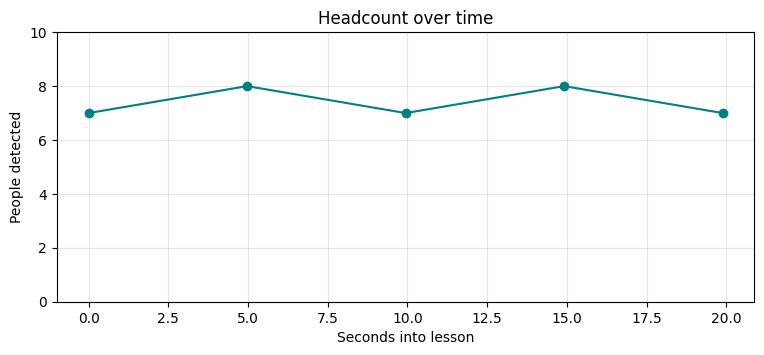

Estimated attendance (median): 7 | Peak: 8


In [39]:
attendance = df.groupby("time_sec")["present"].first()
plt.figure(figsize=(9, 3.5))
attendance.plot(marker="o", color="teal")
plt.title("Headcount over time"); plt.xlabel("Seconds into lesson"); plt.ylabel("People detected")
plt.ylim(0, attendance.max() + 2); plt.grid(alpha=.3); plt.show()
print(f"Estimated attendance (median): {int(attendance.median())} | Peak: {int(attendance.max())}")

**Q2 · What were students doing?** Share of all detections per behaviour. We drop low-confidence guesses (< 50%) because they are close to coin-flips.

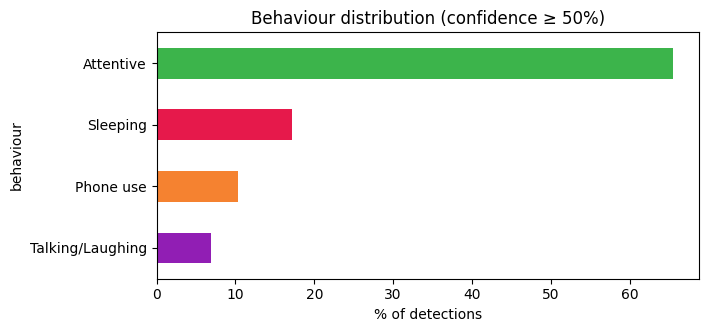

Kept 29 of 37 detections after the confidence filter.


In [40]:
valid = df.dropna(subset=["behaviour"])
confident = valid[valid["confidence"] >= 0.5]
share = confident["behaviour"].value_counts(normalize=True).mul(100).round(1)
share.plot(kind="barh", color=[tuple(c/255 for c in COLORS[b]) for b in share.index], figsize=(7, 3.2))
plt.xlabel("% of detections"); plt.title("Behaviour distribution (confidence ≥ 50%)"); plt.gca().invert_yaxis(); plt.show()
print(f"Kept {len(confident)} of {len(valid)} detections after the confidence filter.")

**Q3 · How did behaviour change during the lesson?** A stacked chart often reveals the story, e.g. attention dropping after 30 minutes.

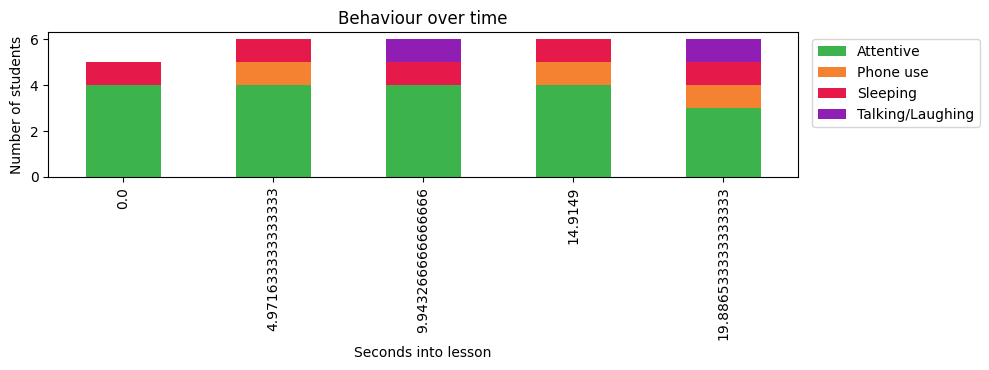

In [41]:
timeline = confident.groupby(["time_sec", "behaviour"]).size().unstack(fill_value=0)
timeline.plot(kind="bar", stacked=True, figsize=(10, 3.8),
              color=[tuple(c/255 for c in COLORS[b]) for b in timeline.columns])
plt.title("Behaviour over time"); plt.xlabel("Seconds into lesson"); plt.ylabel("Number of students")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left"); plt.tight_layout(); plt.show()

**Q4 · Participation:** how often were hands raised?

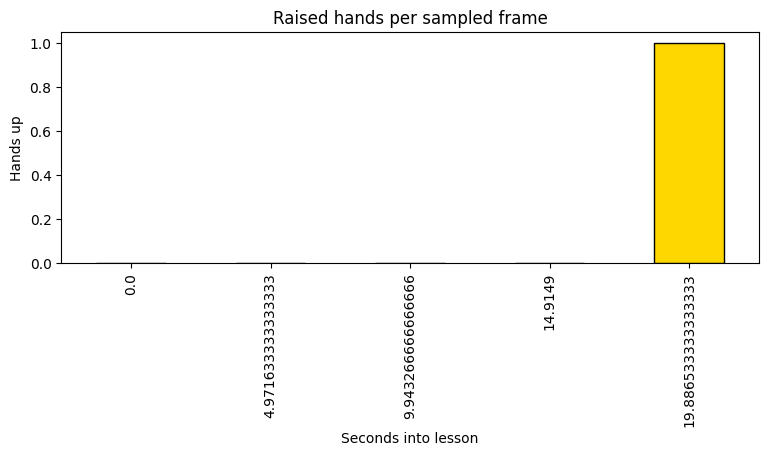

Total hand-raise detections: 1


In [42]:
hands = df.groupby("time_sec")["hand_raised"].sum()
hands.plot(kind="bar", color="gold", edgecolor="black", figsize=(9, 3))
plt.title("Raised hands per sampled frame"); plt.xlabel("Seconds into lesson"); plt.ylabel("Hands up"); plt.show()
print("Total hand-raise detections:", int(hands.sum()))

**Q5 · One summary number: Engagement Score**
A simple, *transparent* rule you can explain to a non-technical audience:

> Engagement = % of confident detections that are **Attentive, Laptop work, or Hand raised**.

⚠️ "Laptop work" could also be gaming, and "Talking" could be a useful group discussion. This is a *rough indicator* and not a grade. Always combine it with the teacher's context.

In [43]:
engaged_mask = confident["behaviour"].isin(["Attentive", "Laptop work"]) | confident["hand_raised"]
engagement = engaged_mask.mean() * 100
print(f"📈 Engagement score: {engagement:.0f}%")

summary = pd.DataFrame({
    "Metric": ["Estimated attendance (median)", "Peak headcount", "Engagement score",
               "Most common behaviour", "Total hand raises"],
    "Value": [int(attendance.median()), int(attendance.max()), f"{engagement:.0f}%",
              share.index[0], int(hands.sum())]})
summary

📈 Engagement score: 69%


,Metric,Value
0,Estimated attendance (median),7
1,Peak headcount,8
2,Engagement score,69%
3,Most common behaviour,Attentive
4,Total hand raises,1


In [44]:
df.to_csv("classroom_insights.csv", index=False)
summary.to_csv("classroom_summary.csv", index=False)
print("Saved classroom_insights.csv and classroom_summary.csv.")

Saved classroom_insights.csv and classroom_summary.csv.


## Step 16 · Limitations and how to improve this (your next steps)

| Limitation | Why it matters | How to improve |
|---|---|---|
| Trained on general action photos, not classrooms | Lighting, camera angle and desks differ → lower accuracy in real use | **Collect & label your own classroom crops** (consent first!) and fine-tune the model |
| No "reading" / "writing" class | Can't detect these yet | Label ~200–500 crops each; add the new classes to `KEEP` |
| CCTV is high & far away → small, blurry people | CNN struggles with low resolution | Use a higher-resolution camera; crop and upscale; filter very small boxes |
| Occlusion (students behind others) | Undercounts attendance | Use the median over many frames; place the camera at the front |
| No identity tracking | Can't say *which* student did what | Intentionally left out for privacy; class-level insights only |
| Hand-raise rule is simple | Stretching or scratching the head can trigger it | Require the raise to persist across 2+ consecutive frames |
| "Talking" vs "laughing" | Visual-only models can't hear | Combine with audio, or rename the class to "Social/Distracted" |

### 🧪 Exercises to level up
1. **Add a class:** put `"clapping"` or `"eating"` into `KEEP`/`FRIENDLY`, retrain, and compare accuracy.
2. **Compare models:** swap MobileNetV2 for `EfficientNetB0` and compare.
3. **Persistence filter:** only count a hand raise if it appears in 2 consecutive frames.
4. **Dashboard:** put the charts in a Streamlit or Looker Studio dashboard.
5. **Bias check:** does accuracy differ by lighting or by how far the person is from the camera? Slice your errors (see the ML framework: *error analysis by slice*).

### 📚 Glossary
- **CNN**: neural network specialised for images.
- **Epoch**: one pass over the training data.
- **Overfitting**: great on training data, poor on new data.
- **Transfer learning**: reusing a model trained on a big dataset.
- **Confidence**: the model's probability for its chosen class.
- **Keypoints / pose**: x,y positions of body joints.
- **Confusion matrix**: table showing which classes get mixed up.

🎉 **Congratulations!** You've built a complete pipeline: data → CNN → detection → insights.